# 1. Prepare and explore Spotify tracks

The root notebook is preserved as an original experiment. This executable copy uses shared helpers in `pipeline_lib.py` so every stage writes to the same isolated run. Launch with `.venv/bin/python run_pipeline.py --profile smoke`.

We clean all raw rows, then optionally take a small stratified sample for testing. A saved train/holdout split is reused throughout the workflow.

In [1]:
from pipeline_lib import RunContext, prepare_data
ctx = RunContext.from_environment("data_processing")
print("Profile:", ctx.config["profile"])
print("Artifacts:", ctx.run_dir)
import pandas as pd
from IPython.display import Image, display
pd.read_csv(ctx.root / 'spotify_tracks_dataset.csv').head()

Profile: full
Artifacts: /Users/anishech/Projects/ML_Spotify/runs/20261021_140544_769703_full


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


Cleaning follows the original notebook: remove missing values and duplicates, convert explicit flags to integers, keep speechiness ≤ 0.7, instrumentalness ≤ 0.9, liveness ≤ 0.8 and nonzero durations. Track identity is retained separately for readable predictions. Original CSV files are never overwritten.

In [2]:
data_summary = prepare_data(ctx)
display(data_summary)

after_missing_values: 113999 rows


after_dedup_track_id: 89740 rows


after_dedup_artists_album_name_track_name: 89379 rows


after_dedup_artists_track_name: 81343 rows


after_dedup_album_name_track_name: 80279 rows


...

after_instrumentalness: 74203 rows


after_liveness: 71945 rows


after_nonzero_duration: 71945 rows


Prepared 71945 modeling rows; 57556 train / 14389 holdout; hits 1825 / 456


,value
raw_rows,114000
after_missing_values,113999
after_dedup_track_id,89740
after_dedup_artists_album_name_track_name,89379
after_dedup_artists_track_name,81343
after_dedup_album_name_track_name,80279
after_speechiness,79433
after_instrumentalness,74203
after_liveness,71945
after_nonzero_duration,71945


Training shape: (57556, 16) Holdout shape: (14389, 16)


,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre,popularity
row_id,,,,,,,,,,,,,,,,
0,230666,0,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic,73
1,149610,0,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic,55
2,210826,0,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic,57
3,201933,0,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic,71
4,198853,0,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic,82


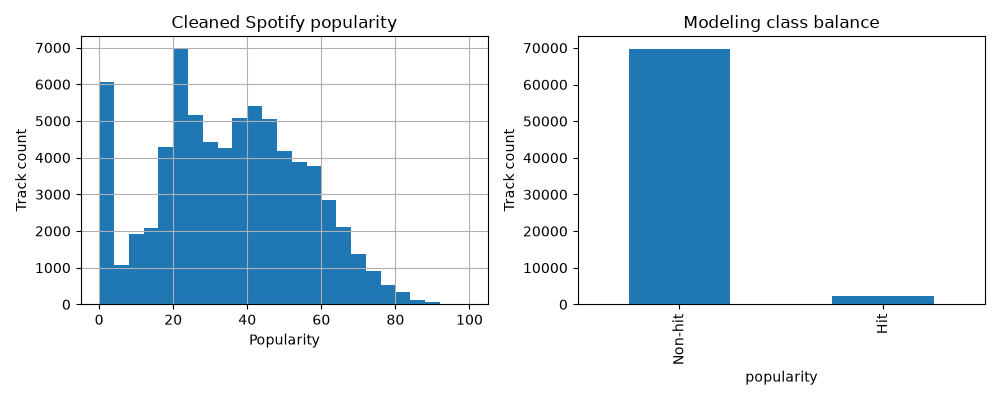

In [3]:
train, holdout = ctx.data()
print('Training shape:', train.shape, 'Holdout shape:', holdout.shape)
display(train.head())
display(Image(filename=str(ctx.path('plots', 'data_distribution.png'))))

The holdout stays separate from fitting and parameter selection. Popularity > 70 defines a hit; this is a Spotify label, not a Billboard chart label. Next: classification.